In [1]:
from qiskit.visualization import plot_bloch_vector
from matplotlib.animation import FuncAnimation
from qiskit.visualization.bloch import Bloch
from IPython.display import Image, display  
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library import get_standard_gate_name_mapping
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt
import numpy as np
from midiutil import MIDIFile


# ALL FUNCTIONS:

def vector_xyz(state):
    """
    Function to translate a complex state into a 3D real vector.
    """
# Extract the complex amplitudes (alpha and beta)
    alpha = state.data[0]
    beta = state.data[1]

    # Compute Cartesian (x, y, z) coordinates 
    x = 2 * np.real(np.conj(alpha) * beta)
    y = 2 * np.imag(np.conj(alpha) * beta)
    z = np.abs(alpha)**2 - np.abs(beta)**2

    return([x, y, z])

    
def vector_spherical(state):
    """
    Function to translate a Cartesian state into spherical coordinates.
    """
    x, y, z = state

    r = np.sqrt(x**2 + y**2 + z**2)
    if r == 0:
        return [0.0, 0.0, 0.0]

    theta = np.arccos(z / r)
    phi = np.arctan2(y, x)

    return [r, theta, phi]


def gates(gate_list, qc=None):
    """
    Function to apply a list of gates to a qubit circuit.
    """
    # Qubits needed based on the largest gate in gate_list
    gate_mapping = get_standard_gate_name_mapping()
    max_qubits = 1 # Change based on number of instruments desired.
    
    for gate_name in gate_list:
        if gate_name in gate_mapping:
            # Check how many qubits this specific gate expects
            max_qubits = max(max_qubits, gate_mapping[gate_name].num_qubits)
            
    # Initialise the QuantumCircuit with the required number of qubits
    if qc is None:
        qc = QuantumCircuit(max_qubits)
    
    states = []
    
    # Initialise all qubits to the '0' state
    for q in range(qc.num_qubits):
        qc.initialize([1, 0], q)
    
    # Apply the gates
    for gate_name in gate_list:
        if hasattr(qc, gate_name):
            gate_method = getattr(qc, gate_name)
            
            # Determine how many qubits this gate method requires
            if gate_name in gate_mapping:
                num_gate_qubits = gate_mapping[gate_name].num_qubits
            else:
                num_gate_qubits = 1 
            
            target_qubits = list(range(num_gate_qubits))
            
            # Call the method unpacking the precise amount of qubits
            gate_method(*target_qubits)
            
            # Calculate and append state tracking
            state = vector_xyz(Statevector(qc))
            states.append(state)
        else:
            print(f"Warning: Gate '{gate_name}' is not a recognized Qiskit method.")

    return states, qc


def get_closest(value, target_dict):
    """
    Function to find the closest key's value based on a midpoint range.
    """
    keys_array = np.array(list(target_dict.keys()))
    values_array = np.array(list(target_dict.values()))
    
    # Find the index of the key with the smallest absolute distance
    closest_idx = np.abs(keys_array - value).argmin()
    return int(values_array[closest_idx])


def update(frame, gate_list):
    """
    Function to change the animation to the next frame.
    """
    b.vectors = []  # Clear previous frame vector paths cleanly

    states = gates(gate_list)[0]
    moving_vector = states[frame]
    b.vectors = list(background_note_vectors)
    b.add_vectors(moving_vector)
    
    gate_color = ["#000000"]  # High-contrast black for the moving gate vector
    gate_width = 2 # Narrower moving vector.
    b.vector_color = background_colors + gate_color
    b.vector_width = background_width
    
    # Render the combined canvas scene
    b.sphere_color = "#DCE7F2"
    b.sphere_alpha = 0.1
    b.render()
        
    return b.axes.artists


    
def spherical_to_cartesian(r, theta, phi):
    """
    Spherical to Cartesian coordinates for setup.
    """
    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)
    return [x, y, z]



def theta_and_phi(states):
    notes = []
    """
    Function to combine theta and phi information.
    """
    for i in range(len(states)):

        theta = vector_spherical(states[i])[1]
        phi = vector_spherical(states[i])[2]
        
        if theta in theta_dict:
            theta_note = theta_dict[theta]
        else:
            theta_note = get_closest(theta, theta_dict)
            
    
        if phi in phi_dict:
            phi_note = phi_dict[phi]
        else:
            phi_note = get_closest(phi, phi_dict)

        note = ((theta_note - 1) * 12) + phi_note
        notes.append(note)
        
    return notes
    



# DICTIONARIES:

# Create dictionaries to map state (r, theta, phi) to integer pitch over middle 7 octaves.
phi_dict = {}
theta_dict = {}
# Assumes normalised state with r = 1.

# Theta => octave.
theta_dict = {
    (np.pi / 4): 1,
    (np.pi * 2 / 4): 2,
    (np.pi * 3 / 4): 3,
    (np.pi * 4 / 4): 4,
    (np.pi * 5 / 4): 5,
    (np.pi * 6 / 4): 6,
    (np.pi * 7 / 4): 7
}

for j in range(24, 36): # Phi = > notes.
    phi_dict.update({(((j - 24) / 6) * np.pi) : j})



(-0.9, 0.9)

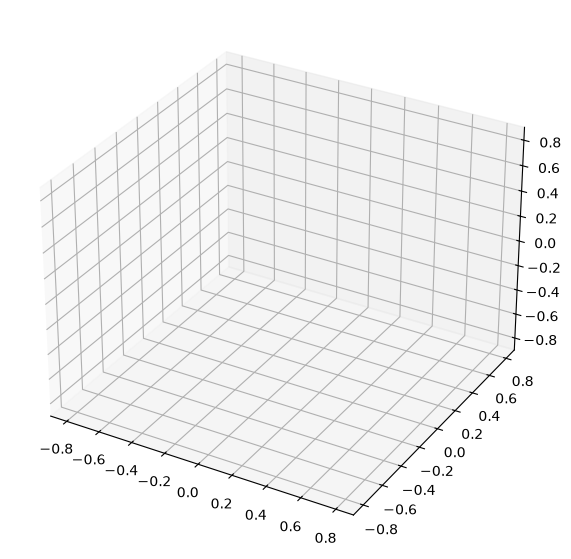

In [2]:
# Set up a 3D canvas, Bloch sphere, background musical vectors.

fig, ax = plt.subplots(subplot_kw=dict(projection="3d", computed_zorder=False), figsize=(7, 7))
b = Bloch(axes=ax)
b.plot_axes_labels = lambda: None # Hide axes labels.

# Arrays for notes and colour mapping.
notes = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
octave_colours = [plt.colormaps["turbo_r"](val) for val in np.linspace(0, 1, 12)]

# Assign even spaced locations for each musical vector.
octave = {}
for i in range(0, 12):
    r = 1
    theta = np.pi / 2 # Octave at circumference.
    phi = (i / 6) * np.pi
    x, y, z = spherical_to_cartesian(r, theta, phi)
            
    octave[notes[i]] = [x, y, z]
    
# Sequentially add vectors and text annotations
for label, coords in octave.items():
    b.add_vectors(coords)
        
    # Move labels 15% farther from the sphere's centre
    label_coords = 1.15 * np.array(coords)
    b.add_annotation(label_coords, label)

background_note_vectors = list(b.fixed_vectors) if hasattr(b, 'fixed_vectors') and b.fixed_vectors else list(b.vectors)
background_colors = octave_colours
background_width = 3

# Setup padding boundaries
limit = 0.9
ax.set_xlim3d(-limit, limit)
ax.set_ylim3d(-limit, limit)
ax.set_zlim3d(-limit, limit)
(-0.9, 0.9)

Please input gates as required, separated by spaces. x y z h id h s sx tdg x id


[60, 24, 24, 36, 36, 24, 24, 36, 36, 40, 40]


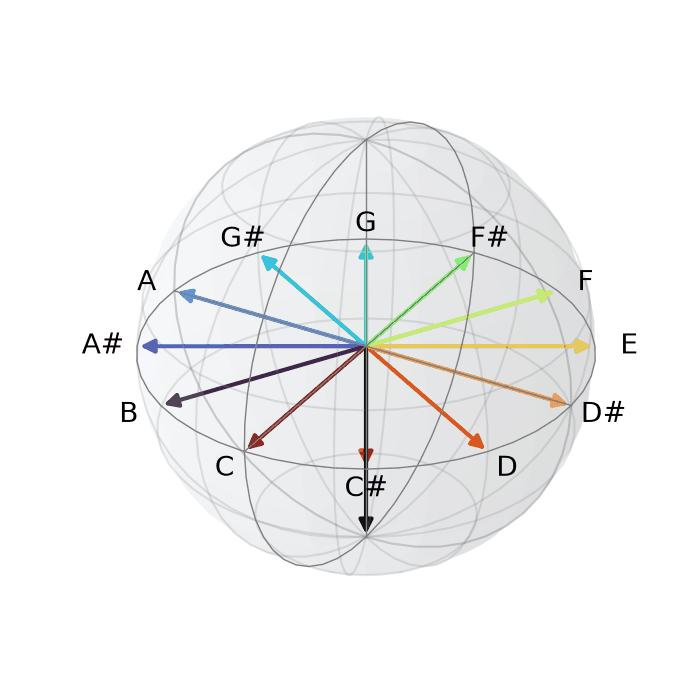

In [3]:
# Frame configurations
gate_list0 = str(input("Please input gates as required, separated by spaces."))
gate_list = gate_list0.split(' ')
states, qc = gates(gate_list)
notes = theta_and_phi(states)
frames_count = len(gate_list)  # Sliced frame count slightly so it compiles instantly
print(notes)

# Build the animation & MIDI
ani = FuncAnimation(fig, update, frames=frames_count, fargs=(gate_list,), interval=200, blit=True)
MyMIDI = MIDIFile(1)

track = 0
time = 0

MyMIDI.addTrackName(track, time, "QC track")
MyMIDI.addTempo(track, time, 120)

track    = 0   # Track numbers are zero-origined
channel  = 0   # MIDI channel number -> number of qubits.
duration = 1   # In beats
volume   = 100 # 0-127, 127 being full volume

for i in range(len(notes)):
    pitch = notes[i]
    time = i
    MyMIDI.addNote(track,channel,pitch,time,duration,volume)

# Save as GIF and MIDI:
with open("bloch_midi_fin.midi", 'wb') as output_file:
    MyMIDI.writeFile(output_file)
gif_path = "bloch_anim_fin.gif"
ani.save(gif_path, writer='pillow', fps=3)

# Disply GIF:
display(Image(filename=gif_path))

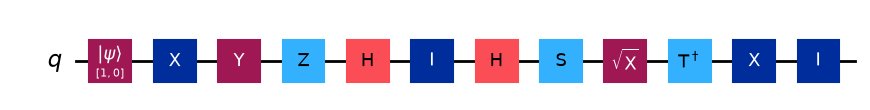

In [4]:
qc.draw("mpl")